## Error Aanalysis

In [1]:
# load CIFAR10 data from kaggle
import os
from google.colab import files

# 1. Upload your kaggle.json file
uploaded = files.upload()

# 2. Create the ~/.kaggle directory if it doesn't exist
os.makedirs('/root/.kaggle', exist_ok=True)

# 3. Move the uploaded kaggle.json file to ~/.kaggle/
!mv kaggle.json /root/.kaggle/

# 4. Set appropriate file permissions (read/write for owner only)
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API key configured successfully!")

Saving kaggle_api.json to kaggle_api.json
mv: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API key configured successfully!


In [2]:
# Install Kaggle library if not already installed
!pip install -q kaggle

# Download the dataset (replace with your dataset's API command)
!kaggle datasets download -d fedesoriano/cifar10-python-in-csv

# Unzip the downloaded dataset into a specific directory
import zipfile

dataset_zip = "cifar10-python-in-csv.zip"  # Replace with the actual zip filename downloaded

with zipfile.ZipFile(dataset_zip, 'r') as zip_ref:
    zip_ref.extractall('dataset_folder')

print("Dataset downloaded and extracted!")

Dataset URL: https://www.kaggle.com/datasets/fedesoriano/cifar10-python-in-csv
License(s): copyright-authors
100% 209M/209M [00:02<00:00, 73.7MB/s]

Dataset downloaded and extracted!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms

In [4]:
device = torch.device("cuda" if torch.cuda.is_available()  else "cpu")
device

device(type='cuda')

In [5]:
train = pd.read_csv('dataset_folder/train.csv')
test = pd.read_csv('dataset_folder/test.csv')

In [6]:
train.shape, test.shape

((50000, 3073), (10000, 3072))

In [7]:
x_train = train.iloc[:, :-1]
y_train = train.iloc[:, -1]
x_test = test.copy()

In [8]:
x_train.shape, y_train.shape, x_test.shape

((50000, 3072), (50000,), (10000, 3072))

In [9]:
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=10000, random_state = 3)

In [10]:
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((40000, 3072), (10000, 3072), (40000,), (10000,))

Create a transformer function that takes a 32x32 image and applies random transformations like cropping, horizontal flip, rotations, and some modifications with brightness, contrast, etc.


In [11]:
from torchvision.transforms import transforms

In [58]:
tf = transforms.Compose([
    transforms.Resize((224, 224)),  #resize to 224,224 (bilinear interpolation)
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
]
)

In [46]:
from PIL import Image
class d_set(Dataset):

  def __init__(self, x: np.ndarray, y: np.ndarray, transform = None):

    self.x = x
    self.y = y
    self.transform = transform

  def __getitem__(self, idx):
    image = self.x[idx].reshape(3, 32, 32).transpose(1, 2, 0).astype(np.uint8)
    image = Image.fromarray(image)  #convert to PIL image for transformation

    if self.transform:
        image = self.transform(image)

    label = torch.tensor(self.y[idx], dtype=torch.long)

    return image, label

  def __len__(self):
    return self.x.shape[0]

In [61]:
train_set = d_set(x_train.values, y_train.values, tf)  # transformations should be applied only on training set
val_set = d_set(x_val.values, y_val.values, tf)

In [62]:
#iterable dataloaders
train_loader = DataLoader(train_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch
val_loader = DataLoader(val_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch

In [63]:
len(train_set), len(val_set)

(40000, 10000)

In [70]:
class_map = {
    0: "airplane",
    1: "automobile",
    2: "bird",
    3: "cat",
    4: "deer",
    5: "dog",
    6: "frog",
    7: "horse",
    8: "ship",
    9: "truck"
}

In [18]:
from torchvision.models import resnet18
from torchvision.transforms import transforms

In [ ]:
# load the resnet architecture (without pretrained weights)
model = resnet18(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, 10)

#load the fine tuned weights into a variable
state_dict = torch.load('resnet18_40k.pth', weights_only = False,
                        map_location='cuda')

model.load_state_dict(state_dict)  #update them in model

<All keys matched successfully>

In [55]:
model = model.to("cuda")

In [65]:
# Function to evaluate model accuracy
def eval_model(model, loader, return_labels = False):
  model.eval()
  with torch.no_grad():
    total = 0
    correct = 0
    preds = []
    true_label = []

    for batch_x, batch_y in loader:

      batch_x, batch_y = batch_x.to(device), batch_y.to(device)
      true_label.extend(batch_y.tolist())

      y_pred = model(batch_x)
      predictions = y_pred.max(axis = 1)[1]
      preds.extend(predictions)

      total = total + batch_x.shape[0]
      correct += (predictions == batch_y).sum().item()

  accuracy = correct / total

  if return_labels:
    return accuracy, true_label, preds

  return accuracy

In [90]:
#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

validation accuracy -> 0.9422


In [91]:
_, true, pred = eval_model(model, val_loader, True)

In [92]:
pred = [x.item() for x in pred]

In [93]:
from sklearn.metrics import classification_report
print(classification_report(true, pred))

              precision    recall  f1-score   support

           0       0.93      0.96      0.95      1032
           1       0.97      0.96      0.97       951
           2       0.94      0.94      0.94      1033
           3       0.86      0.91      0.89       994
           4       0.94      0.94      0.94       918
           5       0.91      0.89      0.90      1006
           6       0.97      0.95      0.96      1043
           7       0.96      0.95      0.96      1040
           8       0.97      0.95      0.96       970
           9       0.96      0.96      0.96      1013

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



Error Analysis

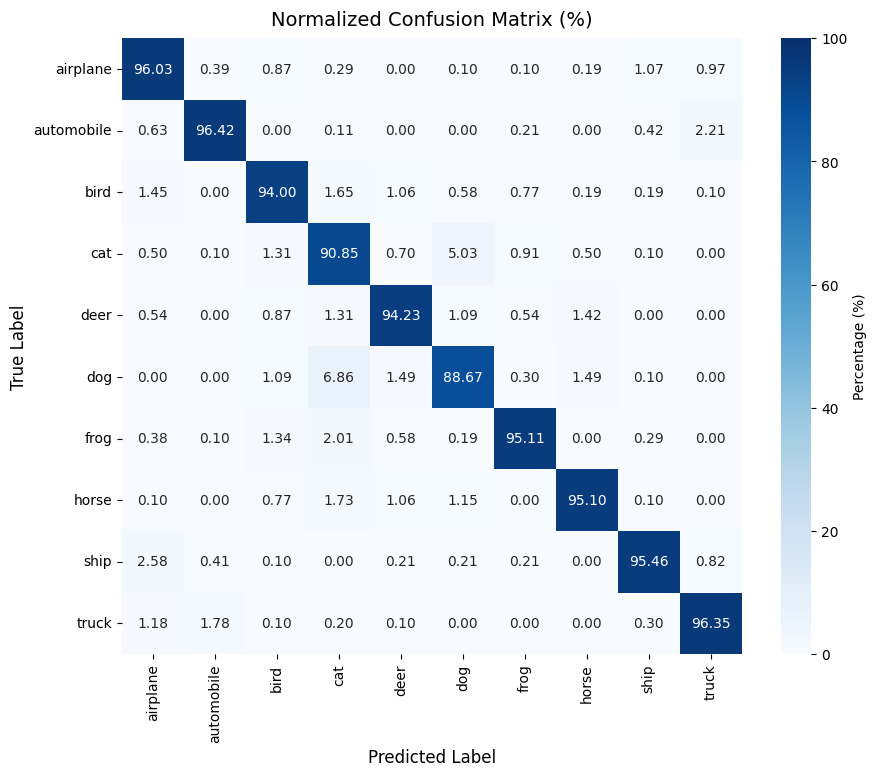

In [94]:
# let's analyze the errors using confution matrix

from sklearn.metrics import confusion_matrix

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# -------------------------------------------------------------------
# 2. Calculate Percentage Confusion Matrix (Row-Normalized)
# -------------------------------------------------------------------
# Compute raw count confusion matrix
cm_raw = confusion_matrix(true, pred)

# Normalize by row sums (actual targets) to get percentages (0.0 to 100.0%)
cm_percent = (cm_raw / cm_raw.sum(axis=1, keepdims=True)) * 100

# -------------------------------------------------------------------
# 4. Plot Heatmaps using Seaborn
# -------------------------------------------------------------------
plt.figure(figsize=(10, 8))

# --- Plot 1: Percentage Confusion Matrix ---
sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Percentage (%)'}
)
plt.title("Normalized Confusion Matrix (%)", fontsize=14, pad=10)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.show()

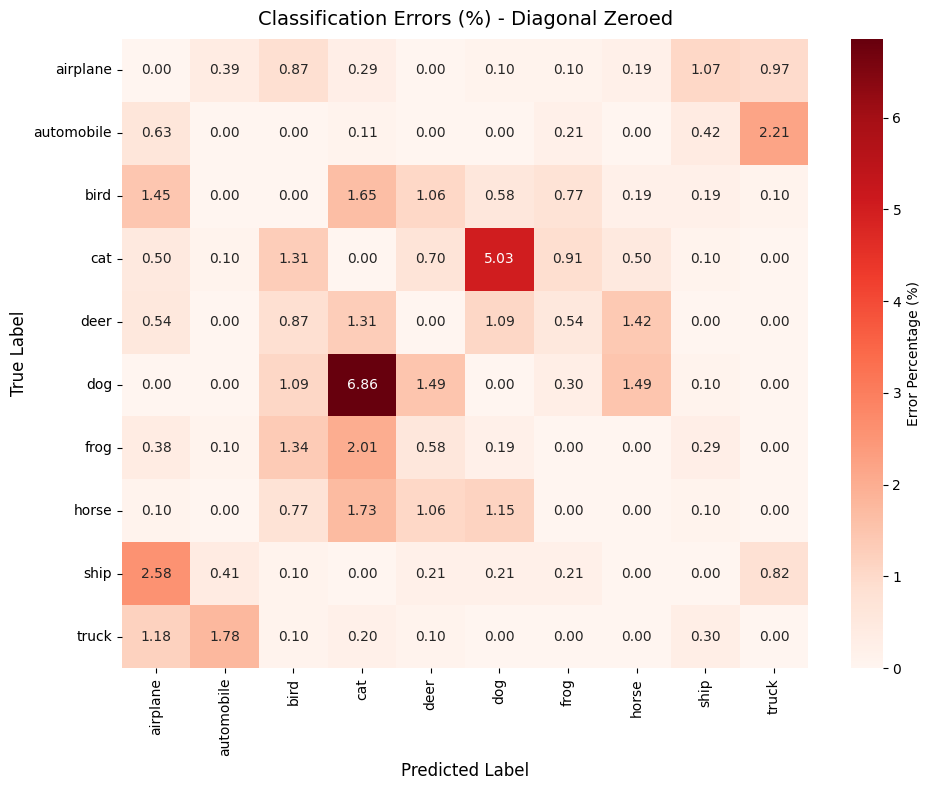

In [95]:
# 3. Create Error Matrix (Zero Out Diagonal)
# -------------------------------------------------------------------
cm_errors = cm_percent.copy()
np.fill_diagonal(cm_errors, 0)

# --- Plot 2: Error Matrix (Diagonal Subtracted/Zeroed) ---
# v_max dynamically set to highlight misclassifications using a warm palette

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_errors,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    vmin=0,
    vmax=np.max(cm_errors),
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Error Percentage (%)'}
)
plt.title("Classification Errors (%) - Diagonal Zeroed", fontsize=14, pad=10)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)

plt.tight_layout()
plt.show()

**Some obvious error we can see here:**

- automobilies misclassified as truck
- ships misscalassified as airplane
- but most importantly, the category dog and cat.
The error on these two is unusually high compared to other categories.
It looks like the model is finding it difficult to differentiate between these two categories.

This should be intuitive that cats and dogs do share a lot of visual features when looked at a distance.
And, the fine details vanish in CIFAR10 images as they are tiny (32x32).



